In [2]:
def readfastq(filename):
    sequences = []
    qualities = []

    with open (filename, "r") as fh:
        while True:
            headers = fh.readline()

            if not headers:
                break

            seq = fh.readline().rstrip()
            fh.readline()
            qual = fh.readline().rstrip()

            sequences.append(seq)
            qualities.append(qual)

    return sequences, qualities

seqs, qual = readfastq("mutant_R1.fastq")

In [3]:
seqs[:5]

['AATGTTGTCACTTGGATTCAAATGACATTTTAAATCTAATTATTCATGAATCGAACTAGTACGAAATGCAATGAGCATCTTGTCTAGTTCGATTTTTTAATGTCTAAAAATGTCGTATATGTAATCAGAGTAGAAAGTGTTGAGGCGTTT',
 'CAAAGTCGTTGGTCATATAAAAAACCGCGTACAGTCAACTATAGATACAATCAAGATAAACTCATGCACAGATTGGGAGATATTTTAGTGCAATATGGAATTCAACATGACACAGGGTTATTACCACATGAATGGCATTATCACATTTCG',
 'TATAAATTCAACTTTGCAACAGAACCATCTAATCTTCAACAAACTGGCCCGTTTGTTGAACTACTCTTTAATAAAATAATTTTTCCGTTCCCAATTCCACATTGCAATAATAGAAAATCCATCTTCATCGGCTTTTTCGTCATCATCTGT',
 'CATGATCAAAAAGCAGCTGATTTATTATTACAAGCACAACGTTTTGGTGTAAAAGAAGATGGTTCAGCAAGTAAAGAACTTGTAGATAGTTATAAATCAGAAATTCTTGTTAAAAAAGACTCAAAAATTAAAAGCTTGAAAGATTTAAAA',
 'CTCAATATCATCGGTGGATTTATTCATCCATCATCTGGTCGTGTCATTATTGATAACGAAATTAAACAACAGCCGTCTCCAGATTGTTTAATGCTATTTCAACATCATAATCTGCTGCCATGGAAAACGATTAATGACAACATTAGGATT']

# QC Data

In [4]:
def phredtoQ(qual):
    Q = []
    for q in qual:
        for phred in q:
            Q.extend([ord(phred)-33])
    
    return Q


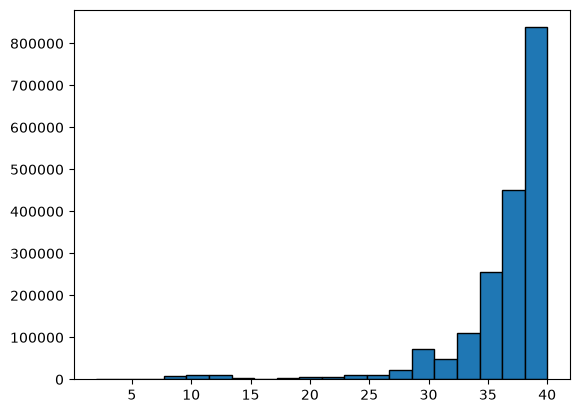

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.hist(phredtoQ(qual), bins=20, edgecolor='black', )
plt.show()

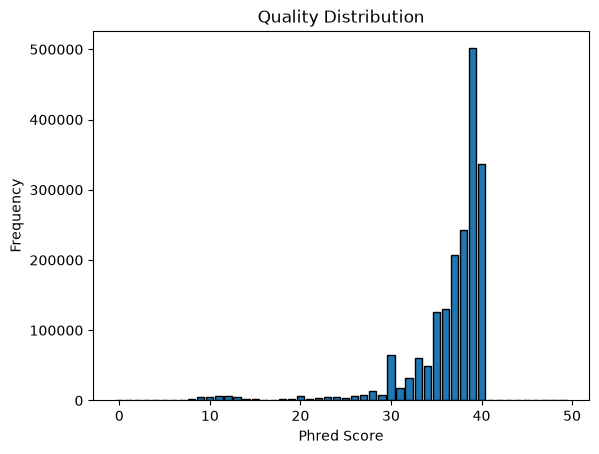

In [6]:

h = [0] * 50

for q in qual:
    for phred in phredtoQ(q):
        if phred < 50:
            h[phred] += 1  
plt.bar (range(len(h)), h, edgecolor='black')
plt.xlabel('Phred Score')
plt.ylabel('Frequency')
plt.title('Quality Distribution')
plt.show()

In [7]:
len(seqs[1])

150

In [8]:
def findGCByPos(seq):

    GC = [0] * len(seq[0])
    total = [0] * len(seq[0])

    for s in seq:
        for i in range(len(s)):
            if s[i] in ('G', 'C', 'g', 'c'):
                GC[i] += 1
            total[i] += 1


    for i in range(len(GC)):

        if total[i] > 0:
            GC[i] /= float(total[i]) 

    return GC    

GC_result = findGCByPos(seqs)

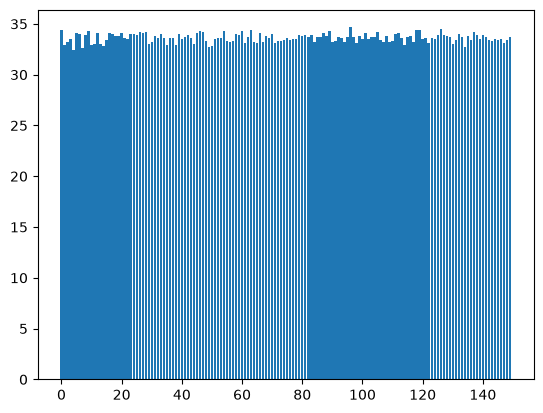

In [9]:
GC_percent = [x * 100 for x in GC_result]

plt.bar(range(len(GC_percent)), GC_percent)

plt.show()

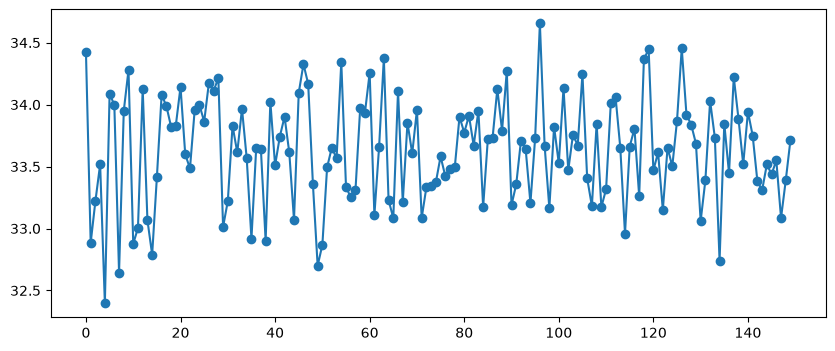

In [23]:
plt.figure(figsize=(10, 4))

plt.plot(range(len(GC_percent)), GC_percent, marker='o')

plt.show()

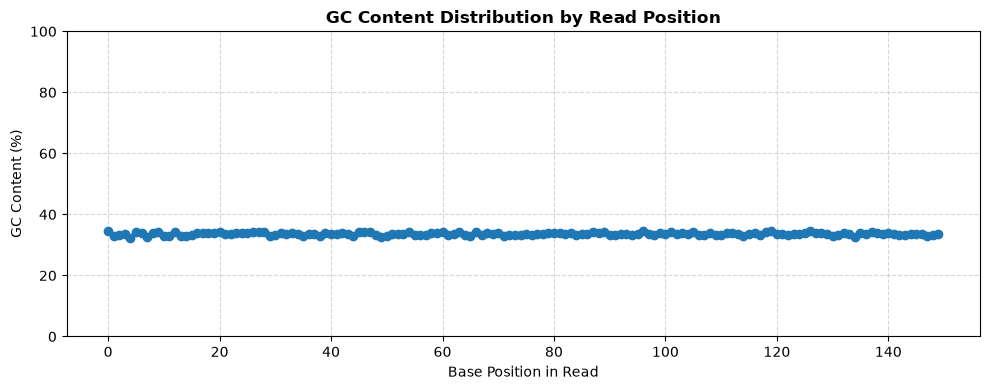

In [ ]:
plt.figure(figsize=(10, 4))

plt.plot(range(len(GC_percent)), GC_percent, marker='o')


plt.title('GC Content Distribution by Read Position', fontsize=12, fontweight='bold')
plt.xlabel('Base Position in Read', fontsize=10)
plt.ylabel('GC Content (%)', fontsize=10)


plt.ylim(0, 100)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [12]:
import collections

count = collections.Counter()
for seq in seqs:
    count.update(seq)

print(count)

Counter({'A': 621612, 'T': 620860, 'C': 314844, 'G': 314684})


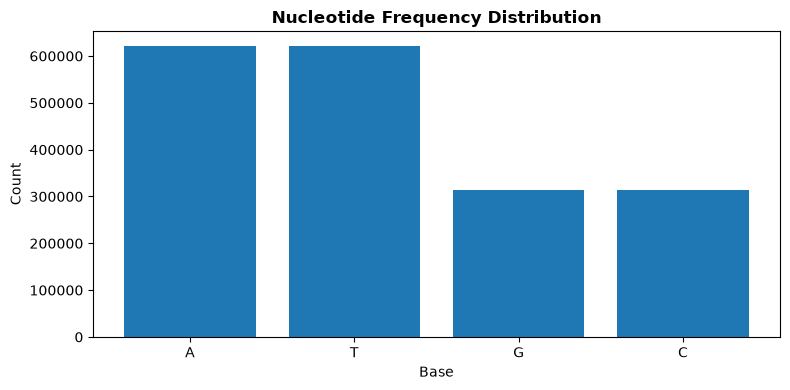

In [25]:
plt.figure(figsize=(8, 4))

plt.bar(count.keys(), count.values())


plt.title('Nucleotide Frequency Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Base', fontsize=10)
plt.ylabel('Count', fontsize=10)

plt.tight_layout()
plt.show()

# Read Alignment


1- Naive exact matching

In [14]:
def naive (p, t):
    occurrences = []
    for i in range(len(t) - len(p) + 1):
        match = True
        for j in range(len(p)):
            if t[i + j] != p[j]:
                match = False
                break
        if match:
            occurrences.append(i)
    return occurrences

    


In [15]:
import urllib.request


url = 'http://d28rh4a8wq0iu5.cloudfront.net/ads1/data/phix.fa'
urllib.request.urlretrieve(url, 'phix.fa')


def readGenome(filename):
    genome = ''
    with open(filename, 'r') as f:
        for line in f:
            if not line.startswith('>'):
                genome += line.rstrip()
    return genome


genome = readGenome('phix.fa')
print("Done! length: ", len(genome))

Done! length:  5386


# Artificial Reads

In [16]:

import random

def generateReads(genome, numReads, readLen):
   
    reads = []
    for _ in range(numReads):
        
        start = random.randint(0, len(genome) - readLen)
      
        reads.append(genome[start : start + readLen])
    return reads

In [17]:
reads = generateReads(genome, 100, 100)
numMatches = 0
for r in reads:
    if naive(r, genome):
        numMatches += 1

print("Number of matches:", numMatches)

Number of matches: 100


# Real Read

In [18]:
import urllib.request

url = 'http://d28rh4a8wq0iu5.cloudfront.net/ads1/data/ERR266411_1.first1000.fastq'


urllib.request.urlretrieve(url, 'Phi_X174.fastq')


('Phi_X174.fastq', <http.client.HTTPMessage at 0x1333e7e4770>)

In [19]:
phix_reads, _ = readfastq("Phi_X174.fastq")

len(phix_reads)

1000

In [20]:
numMatches_2 = 0
for r in phix_reads:
    r_prefix = r[:30]
    if naive(r_prefix, genome):
        numMatches_2 += 1
print("Number of matches (Method 2): ", numMatches_2, "/ 1000")


Number of matches (Method 2):  459 / 1000


In [21]:
def reverseComplement(s):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A', 'N': 'N'}
    t = ''
    for base in s:
        t = complement[base] + t
    return t

In [22]:
numMatches_2 = 0
for r in phix_reads:
    r_prefix = r[:30]
    if naive(r_prefix, genome) or naive(reverseComplement(r_prefix), genome):
        numMatches_2 += 1
print("Number of matches (Method 2): ", numMatches_2, "/ 1000")


Number of matches (Method 2):  932 / 1000
